### Subgraph

LangGraph에서는 별도로 만든 그래프를 부모 그래프의 노드로 등록할 수 있다. 이렇게 다른 그래프에 포함된 그래프를 **Subgraph**라 한다.

### Subgraph를 사용하는 이유

- **재사용**: 미리 만든 그래프를 여러 워크플로우의 노드로 활용할 수 있다.
- **개발·관리 용이**: 복잡한 흐름을 역할별 그래프로 나누어 구현하고 테스트할 수 있다. 부모 그래프에서는 전체 작업 순서에 집중한다.
- **State 분리**: Subgraph가 내부 작업 데이터를 별도로 관리하고, 부모와 필요한 입력·출력만 주고받도록 구성할 수 있다.

단순한 작업은 일반 노드로도 충분하다. Subgraph는 여러 단계로 구성된 작업 흐름을 하나의 단위로 묶어 관리하거나 재사용할 때 장점이 크다.

In [1]:
from typing import Annotated, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

load_dotenv()

MODEL_NAME = "gemini-3.6-flash"
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

### 같은 State 스키마를 공유하는 경우

부모와 Subgraph의 State 스키마가 같으면, **컴파일된 그래프를 그대로 `add_node`에 전달**하면 된다.

부모와 두 Subgraph는 `messages`와 `research` 필드를 가진 같은 `AgentState`를 사용한다. 같은 State 스키마를 사용해도 각 노드는 필요한 필드만 갱신할 수 있다.

- `messages`: 사용자 요청과 최종 보고서를 저장한다.
- `research`: 리서치 Subgraph가 조사 결과를 저장하고, 작성 Subgraph가 보고서 작성에 사용한다.

노드가 반환하는 값은 State의 변경분이다. 반환하지 않은 필드는 기존 값을 유지한다.

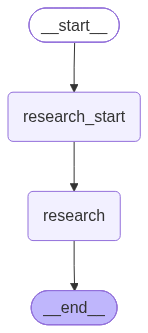

In [3]:
# 공통 State
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    research: str


# 리서치 Subgraph
def research_start_node(state: AgentState):
    print("리서치 작업을 시작합니다.")
    return {}


def research_node(state: AgentState):
    system = SystemMessage(content="너는 리서치 전문가다. 주어진 주제의 핵심 사실 3개를 정리해.")
    messages = [system] + state["messages"]
    response = llm.invoke(messages)
    return {"research": response.text}

research_builder = StateGraph(AgentState)
research_builder.add_node("research_start", research_start_node)
research_builder.add_node("research", research_node)
research_builder.add_edge(START, "research_start")
research_builder.add_edge("research_start", "research")
research_builder.add_edge("research", END)
research_graph = research_builder.compile()

display(Image(research_graph.get_graph().draw_mermaid_png()))

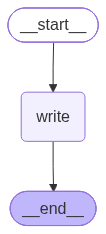

In [6]:
# 작성 Subgraph
def writing_node(state: AgentState):
    system = SystemMessage(content="너는 보고서 작성 전문가다. 사용자 요청과 조사 결과를 바탕으로 간결한 보고서를 작성해.")
    request = HumanMessage(
        content=f"다음 조사 결과로 보고서를 작성해.\n\n{state['research']}"
    )
    messages = [system] + state["messages"] + [request]
    response = llm.invoke(messages)
    return {"messages": [response]}

writing_builder = StateGraph(AgentState)
writing_builder.add_node("write", writing_node)
writing_builder.add_edge(START, "write")
writing_builder.add_edge("write", END)
writing_graph = writing_builder.compile()

display(Image(writing_graph.get_graph().draw_mermaid_png()))

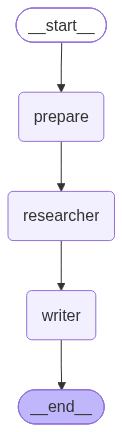

In [7]:
# 부모 그래프: Subgraph를 노드로 등록
def prepare_node(state: AgentState):
    print("요청 처리를 시작합니다.")
    return {}


parent_builder = StateGraph(AgentState)

# 일반 노드
parent_builder.add_node("prepare", prepare_node)

# 컴파일된 그래프를 그대로 노드로 추가한다
parent_builder.add_node("researcher", research_graph)
parent_builder.add_node("writer", writing_graph)

parent_builder.add_edge(START, "prepare")
parent_builder.add_edge("prepare", "researcher")
parent_builder.add_edge("researcher", "writer")
parent_builder.add_edge("writer", END)

parent_graph = parent_builder.compile()

display(Image(parent_graph.get_graph().draw_mermaid_png()))

### Subgraph 실행 과정 스트리밍

기본값인 `subgraphs=False`에서는 부모 그래프의 노드 결과만 받는다. 이때 Subgraph는 부모 그래프의 노드 하나로 표시된다. `subgraphs=True`를 지정하면 부모 그래프뿐 아니라 내부 Subgraph의 노드에서 발생한 결과도 함께 받을 수 있다.

`subgraphs=False`에서는 `chunk`를 반환하고, `subgraphs=True`에서는 `(namespace, chunk)`를 반환한다.

- `namespace`: 이벤트가 발생한 그래프의 경로이다.
- `chunk`: 해당 실행 단계에서 변경된 State이다. `stream_mode="updates"`에서는 `{노드 이름: 변경된 State}` 형태로 전달된다.

두 실행 결과를 비교하면 Subgraph 내부 노드가 스트림에 추가되는 것을 확인할 수 있다.

### Subgraph 내부 실행 제외

In [8]:
for chunk in parent_graph.stream(
    {"messages": [HumanMessage(content="LangGraph의 Subgraph 기능에 대해 정리해줘.")]},
    # subgraphs=False,
    stream_mode="updates",
):
    for node_name, state in chunk.items():
        print("=" * 60)
        print("Graph: parent_graph")
        print(f"Node: {node_name}")
        if state and state.get("research"):
            print(f"research: {state['research'][:300]}")
        if state and state.get("messages"):
            print(f"messages: {state['messages'][-1].text[:300]}")
        if not state:
            print(state)
        print()

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


요청 처리를 시작합니다.
Graph: parent_graph
Node: prepare
None

리서치 작업을 시작합니다.
Graph: parent_graph
Node: researcher
research: 리서치 전문가로서 LangGraph의 **SubGraph(서브그래프)** 기능에 대한 핵심 사실 3가지를 정리해 드립니다.

---

### 1. 모듈화 및 재사용성 극대화 (복잡성 분리)
* **내용:** 서브그래프는 거대하고 복잡한 LLM 워크플로우를 작은 단위의 독립된 그래프로 분할하여 개발할 수 있게 합니다.
* **의의:** 특정 기능(예: 웹 검색 전담 그래프, 코드 실행 전담 그래프)을 하나의 모듈처럼 만들어 메인 그래프의 노드로 삽입할 수 있으며, 다른 프로젝트에서도 쉽게 재사용할 수 있습니다.

### 2. 독립적인
messages: LangGraph의 Subgraph 기능에 대해 정리해줘.

Graph: parent_graph
Node: writer
research: 리서치 전문가로서 LangGraph의 **SubGraph(서브그래프)** 기능에 대한 핵심 사실 3가지를 정리해 드립니다.

---

### 1. 모듈화 및 재사용성 극대화 (복잡성 분리)
* **내용:** 서브그래프는 거대하고 복잡한 LLM 워크플로우를 작은 단위의 독립된 그래프로 분할하여 개발할 수 있게 합니다.
* **의의:** 특정 기능(예: 웹 검색 전담 그래프, 코드 실행 전담 그래프)을 하나의 모듈처럼 만들어 메인 그래프의 노드로 삽입할 수 있으며, 다른 프로젝트에서도 쉽게 재사용할 수 있습니다.

### 2. 독립적인
messages: # [보고서] LangGraph Subgraph(서브그래프) 기능 핵심 분석

---

## 1. 개요
본 보고서는 LangGraph의 핵심 기능인 **Subgraph(서브그래프)**의 주요 특징과 도입 효과를 분석하여 정리함. Subgraph는 복잡한 LLM 워크플로우의 개발 생산성과 유연성을 극대화하는 모듈화 기술임.

---

### Subgraph 내부 실행 포함

In [9]:
for namespace, chunk in parent_graph.stream(
    {"messages": [HumanMessage(content="LangGraph의 Subgraph 기능에 대해 정리해줘.")]},
    subgraphs=True,
    stream_mode="updates",
):
    for node_name, state in chunk.items():
        print("=" * 60)
        print(f"Graph: {namespace}")
        print(f"Node: {node_name}")
        if state and state.get("research"):
            print(f"research: {state['research'][:300]}")
        if state and state.get("messages"):
            print(f"messages: {state['messages'][-1].text[:300]}")
        if not state:
            print(state)
        print()

요청 처리를 시작합니다.
Graph: ()
Node: prepare
None

리서치 작업을 시작합니다.
Graph: ('researcher:6d45d2f7-eaba-926d-fda6-174ac4be1e78',)
Node: research_start
None

Graph: ('researcher:6d45d2f7-eaba-926d-fda6-174ac4be1e78',)
Node: research
research: 리서치 전문가로서 LangGraph의 **Subgraph(서브그래프)** 기능에 대한 3가지 핵심 사실을 정리해 드립니다.

---

### 1. 복잡한 워크플로우의 모듈화 및 재사용성 제공
* **핵심 내용:** Subgraph는 독립적인 하나의 그래프를 다른 부모 그래프(Parent Graph)의 **단일 노드(Node)처럼 포함**시켜 사용하는 기능입니다.
* **효과:** 거대하고 복잡한 LLM 워크플로우를 작은 단위로 분할하여 개발할 수 있어 코드의 가독성과 유지보수성이 크게 향상되며, 작성한 Subgraph를 다른 프로젝

Graph: ()
Node: researcher
research: 리서치 전문가로서 LangGraph의 **Subgraph(서브그래프)** 기능에 대한 3가지 핵심 사실을 정리해 드립니다.

---

### 1. 복잡한 워크플로우의 모듈화 및 재사용성 제공
* **핵심 내용:** Subgraph는 독립적인 하나의 그래프를 다른 부모 그래프(Parent Graph)의 **단일 노드(Node)처럼 포함**시켜 사용하는 기능입니다.
* **효과:** 거대하고 복잡한 LLM 워크플로우를 작은 단위로 분할하여 개발할 수 있어 코드의 가독성과 유지보수성이 크게 향상되며, 작성한 Subgraph를 다른 프로젝
messages: LangGraph의 Subgraph 기능에 대해 정리해줘.

Graph: ('writer:7208facf-0394-ceb7-b571-13ab8061a332',)
Node: write
messages: # [보고서]

### 부모와 Subgraph의 State가 다른 경우

앞에서는 부모와 Subgraph가 같은 State 스키마를 공유했다. State 전체 구조가 달라도, 주고받을 필드의 이름과 데이터 형식이 호환되면 **컴파일된 Subgraph를 그대로 `add_node`에 전달**할 수 있다.

부모와 Subgraph가 주고받을 데이터의 필드 이름이나 형식이 다르면, **래퍼 함수**에서 입력·출력을 변환한다.

- **필드 이름이 다른 경우**: 부모의 `analysis_result`와 Subgraph의 `analysis`처럼 같은 데이터를 서로 다른 이름으로 저장할 때
- **데이터 형식이 다른 경우**: 부모는 `messages`에 메시지 목록을 저장하지만, Subgraph는 `request`에 요청 문자열을 받을 때

기존 그래프를 다른 State 구조의 부모 그래프에서 재사용할 때 이러한 변환이 필요할 수 있다.

다음 예제는 사용자가 요청한 주제를 분석한 뒤 보고서로 작성한다. 래퍼 함수는 부모의 마지막 사용자 메시지를 Subgraph의 `request`로 전달하고, 반환된 `analysis`를 부모의 `analysis_result`에 저장한다. 최종 보고서는 `messages`에 추가한다.

In [10]:
# Subgraph State
class AnalysisState(TypedDict):
    request: str
    analysis: str


def analysis_node(state: AnalysisState):
    system = SystemMessage(content="사용자가 요청한 주제를 분석하여 핵심 쟁점 3개와 각각의 장단점을 정리해.")
    response = llm.invoke([system, HumanMessage(content=state["request"])])
    return {"analysis": response.text}


analysis_builder = StateGraph(AnalysisState)
analysis_builder.add_node("analyze", analysis_node)
analysis_builder.add_edge(START, "analyze")
analysis_builder.add_edge("analyze", END)
analysis_graph = analysis_builder.compile()

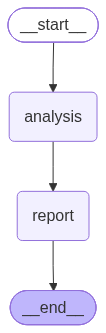

In [11]:
# 부모 State
class ParentState(TypedDict):
    messages: Annotated[list, add_messages]
    analysis_result: str


# 래퍼 함수: 부모 State → Subgraph State → 부모 State
def analysis_wrapper(state: ParentState):
    sub_input = {"request": state["messages"][-1].text}
    sub_result = analysis_graph.invoke(sub_input)
    return {"analysis_result": sub_result["analysis"]}


def report_node(state: ParentState):
    system = SystemMessage(content="분석 결과를 바탕으로 간결한 보고서를 작성해.")
    response = llm.invoke([system, HumanMessage(content=state["analysis_result"])])
    return {"messages": [response]}


parent_builder = StateGraph(ParentState)
parent_builder.add_node("analysis", analysis_wrapper)  # 래퍼 함수를 노드로 등록
parent_builder.add_node("report", report_node)
parent_builder.add_edge(START, "analysis")
parent_builder.add_edge("analysis", "report")
parent_builder.add_edge("report", END)

diff_state_graph = parent_builder.compile()
display(Image(diff_state_graph.get_graph().draw_mermaid_png()))

In [12]:
for namespace, chunk in diff_state_graph.stream(
    {"messages": [HumanMessage(content="AI Agent 도입의 장점과 한계를 분석해줘.")]},
    subgraphs=True,
    stream_mode="updates",
):
    for node_name, state in chunk.items():
        print("=" * 60)
        print(f"Graph: {namespace}")
        print(f"Node: {node_name}")
        if state and state.get("messages"):
            print(state["messages"][-1].text[:300])
        else:
            print(state)
        print()


Graph: ('analysis:18db72ac-c85f-fa74-4784-84e5721b8395',)
Node: analyze
{'analysis': 'AI Agent(인공지능 에이전트)는 단순히 질문에 답하는 생성형 AI를 넘어, **목표를 달성하기 위해 스스로 계획을 세우고 도구를 사용하며 작업을 수행하는 자율형 AI**를 의미합니다. \n\n기업 및 산업 현장에서 AI Agent 도입 시 고려해야 할 **3가지 핵심 쟁점과 각각의 장단점**을 분석해 드립니다.\n\n---\n\n### 쟁점 1. 업무 자동화의 범위와 생산성 혁신 (작업 수행 능력)\nAI Agent가 단순 반복 업무를 넘어 복잡한 멀티스텝(Multi-step) 워크플로우를 스스로 판단하여 처리할 수 있는가에 대한 쟁점입니다.\n\n*   **장점 (Benefits)**\n    *   **자율적 워크플로우 완수:** 기존 AI와 달리 "데이터 수집 → 분석 → 보고서 작성 → 이메일 발송"과 같은 연쇄적 업무를 인간의 개입 없이 스스로 완수합니다.\n    *   **24/7 연중무휴 생산성:** 시공간의 제약 없이 정밀한 업무 처리가 가능하여 운영 비용을 획기적으로 절감합니다.\n    *   **확장성(Scalability):** 업무량이 폭증해도 추가 인력 채용 없이 AI Agent의 스케일아웃(Scale-out)을 통해 즉각 대응할 수 있습니다.\n*   **단점 및 한계 (Limitations)**\n    *   **예외 상황 대응력 부족:** 규정된 로직이나 데이터 범위를 벗어나는 돌발 변수(Edge case) 발생 시 유연한 문제 해결 능력이 떨어집니다.\n    *   **초기 구축 및 연동 비용:** 기존 기업 내 시스템(ERP, CRM 등) 및 API와 AI Agent를 안전하게 연결하는 데 상당한 시간과 기술적 비용이 소요됩니다.\n\n---\n\n### 쟁점 2. 신뢰성과 통제 가능성 (기술적 안전성 및 보안)\nAI Agent에게 자율적 권한(Action)을 부

### 실습: 학습 콘텐츠 생성 그래프

사용자가 입력한 학습 주제를 설명하고, 설명 내용을 바탕으로 확인 문제 3개를 생성하는 그래프를 구현한다.

- 부모의 `LearningState`는 `topic`, `explanation`, `quiz`를 저장한다.
- 설명 Subgraph는 부모와 같은 `LearningState`를 사용하며, `topic`을 받아 `explanation`을 갱신한다.
- 퀴즈 Subgraph는 별도의 `QuizState`를 사용하며, `source_text`를 받아 `questions`를 생성한다.
- 래퍼 함수는 `explanation`을 `source_text`로 전달하고, 반환된 `questions`를 부모의 `quiz`에 저장한다.
- 부모 그래프는 `설명 → 퀴즈 생성` 순서로 실행한다.
- `{"topic": "LangGraph의 State와 Reducer"}`를 입력하고, `subgraphs=True`로 내부 실행 과정을 확인한다.

State에는 작업 데이터를 저장하고, 각 노드는 LLM을 호출할 때 메시지를 구성한다.

In [17]:
class LearningState(TypedDict):
    topic: str
    explanation: str
    quiz: str


def explanation_node(state: LearningState):
    system = SystemMessage(
        content="너는 개념 설명 전문가다. 학습 주제를 초보자도 이해할 수 있게 설명해."
    )
    response = llm.invoke([system, HumanMessage(content=state["topic"])])
    return {"explanation": response.text}


# TODO: LearningState를 사용하는 설명 Subgraph를 만들고 컴파일한다.

builder = StateGraph(LearningState)
builder.add_node('explanation_node', explanation_node)

builder.add_edge(START, 'explanation_node')
builder.add_edge('explanation_node', END)

explanation_graph = builder.compile()

result = explanation_graph.invoke({'topic' : '랭그래프의 서브그래프'})
print(result['explanation'])

**랭그래프(LangGraph)의 서브그래프(Subgraph)**를 아주 쉽게 설명해 드릴게요!

---

### 💡 한 줄 요약
서브그래프는 **"작은 그래프 여러 개를 합쳐서 만드는 큰 복합 로봇"**에서 **'작은 부품 복합체'**와 같습니다. 즉, **"그래프 안에 들어가는 또 다른 독립된 그래프"**를 의미합니다.

---

### 🏢 비유로 이해하기: "회사 업무 시스템"

대기업의 업무 처리 과정을 생각해 볼까요?

1. **메인 그래프 (회사 전체 시스템)**
   * 고객의 요청이 들어오면 "이건 환불 요청이군! 환불팀으로 보내자" 하고 분류합니다.
2. **서브그래프 (환불 전담팀)**
   * 환불팀 내부에는 자신들만의 복잡한 일하는 순서가 있습니다.
   * `영수증 확인` ➔ `재고 확인` ➔ `승인 요청` ➔ `입금 처리`
3. **결과 제출**
   * 환불팀이 내부적으로 일을 다 마치고 "환불 완료되었습니다!"라는 최종 결과만 메인 시스템에 알려줍니다.

여기서 **'환불팀 내부의 일하는 과정'** 전체가 바로 **서브그래프(Subgraph)**입니다.

---

### 🤔 왜 서브그래프를 쓸까요? (장점)

복잡한 AI 프로그램을 만들 때 서브그래프를 사용하면 다음과 같은 엄청난 장점이 있습니다.

1. **코드가 깔끔해집니다 (모듈화)**
   * 메인 그래프에 모든 단계(100개쯤 되는 과정)를 다 그려 넣으면 어지럽고 읽기 힘듭니다. 
   * "검색 기능", "결제 기능" 등을 서브그래프 상자로 포장해 두면 메인 그래프는 아주 간결하고 보기 쉬워집니다.

2. **재사용이 가능합니다 (부품화)**
   * 한 번 잘 만들어둔 서브그래프(예: '사용자 인증 서브그래프')는 다른 AI 시스템을 만들 때도 그대로 가져다 쓸 수 있습니다.

3. **여럿이서 나누어 개발할 수 있습니다 (팀 협업)**
   * A 개발자는 '문서 요약 서브그래프'를 만들고, B 개발자는 '이메일 발송 서브그래프'를 만든 뒤, 나중에 둘을 랭그래프로

In [19]:
class QuizState(TypedDict):
    source_text: str
    questions: str


def quiz_node(state: QuizState):
    system = SystemMessage(
        content="너는 퀴즈 출제 전문가다. 설명 내용만 활용해 확인 문제 3개를 만들어."
    )
    response = llm.invoke([system, HumanMessage(content=state["source_text"])])
    return {"questions": response.text}


# TODO: QuizState를 사용하는 퀴즈 Subgraph를 만들고 컴파일한다.

builder = StateGraph(QuizState)
builder.add_node('quiz_node', quiz_node)

builder.add_edge(START, 'quiz_node')
builder.add_edge('quiz_node', END)

quiz_graph = builder.compile()

result = quiz_graph.invoke({'source_text' : "파이썬은 프로그래밍 언어다. 쉽고 빠르다. ai agent를 만드는데 사용된다."})

print(result)
print(result['questions'])
# TODO: 래퍼 함수에서 explanation을 source_text로 전달하여 퀴즈 Subgraph를 호출하고,
#       반환된 questions를 부모 State의 quiz에 저장한다.

# 부모의 노드.
def quiz_wrapper(state: LearningState):
    explanation = state['explanation']
    result = quiz_graph.invoke({'source_text': explanation})

    return {
        'quiz' : result['questions']
    }


{'source_text': '파이썬은 프로그래밍 언어다. 쉽고 빠르다. ai agent를 만드는데 사용된다.', 'questions': '제공된 설명을 바탕으로 작성한 확인 문제 3개와 정답입니다.\n\n---\n\n**[확인 문제]**\n\n**1. 파이썬은 어떤 종류의 언어인가요?**\n* **정답:** 프로그래밍 언어\n\n**2. 설명에 언급된 파이썬의 대표적인 특징 두 가지는 무엇인가요?**\n* **정답:** 쉽고 빠르다 (쉬움, 빠름)\n\n**3. 파이썬은 무엇을 만드는 데 사용된다고 설명되어 있나요?**\n* **정답:** AI agent (AI 에이전트)'}
제공된 설명을 바탕으로 작성한 확인 문제 3개와 정답입니다.

---

**[확인 문제]**

**1. 파이썬은 어떤 종류의 언어인가요?**
* **정답:** 프로그래밍 언어

**2. 설명에 언급된 파이썬의 대표적인 특징 두 가지는 무엇인가요?**
* **정답:** 쉽고 빠르다 (쉬움, 빠름)

**3. 파이썬은 무엇을 만드는 데 사용된다고 설명되어 있나요?**
* **정답:** AI agent (AI 에이전트)


In [20]:
# TODO: 설명 Subgraph와 퀴즈 래퍼를 부모 그래프의 노드로 등록한다.
builder = StateGraph(LearningState)
builder.add_node('explanation', explanation_graph) # node가 graph 그 자체
builder.add_node('quiz', quiz_wrapper) # node가 graph를 wrapping한 함수.

builder.add_edge(START, 'explanation')
builder.add_edge('explanation', 'quiz')
builder.add_edge('quiz', END)

parent_graph = builder.compile()

# TODO: START → 설명 → 퀴즈 → END 순서로 연결하고 컴파일한다.


# TODO: 완성한 그래프를 subgraphs=True, stream_mode="updates"로 실행한다.
# 입력: {"topic": "LangGraph의 State와 Reducer"}
# 각 이벤트의 namespace, 노드 이름, State 변경분을 출력한다.

for namespace, chunk in parent_graph.stream(
    {'topic' : 'LangGraph의 State와 Reducer'},
    subgraphs=True,
    stream_mode="updates",
):
    for node_name, state in chunk.items():
        print("=" * 60)
        print(f"Graph: {namespace}")
        print(f"Node: {node_name}")
        if state and state.get("messages"):
            print(state["messages"][-1].text[:300])
        else:
            print(state)
        print()


Graph: ('explanation:647b3b7b-0032-5ab2-adfd-765add8302a3',)
Node: explanation_node
{'explanation': '안녕하세요! 개념 설명 전문가입니다. \n\nAI 앱을 만들 때 \'기억력\'을 부여하는 프레임워크인 **LangGraph(랭그래프)**에서 가장 중요한 두 가지 개념, **State(상태)**와 **Reducer(리듀서)**를 초보자 눈높이에 맞춰 아주 쉽게 설명해 드릴게요.\n\n---\n\n### 💡 한 줄 요약\n* **State** = AI 작업실 한가운데에 있는 **\'공유 노트\'**\n* **Reducer** = 공유 노트를 **\'업데이트하는 규칙\'**\n\n---\n\n### 1. State (상태) : "모두가 같이 보는 공유 노트"\n\nLangGraph는 여러 AI(노드, Node)들이 협동해서 하나의 일을 처리하는 시스템입니다. 이때 각 AI가 "지금까지 무슨 일이 있었지?"를 알기 위해 **서로 공유하는 메모장**이 필요한데, 이것이 바로 **State**입니다.\n\n* **역할:** 현재 앱의 모든 데이터(대화 내역, 사용자 이름, 검색 결과 등)를 저장합니다.\n* **비유:** 팀 프로젝트를 할 때 쓰는 **\'공유 Google Doc\'**과 같습니다.\n* **동작 방식:** A 작업자가 노트를 읽고 내용을 추가한 뒤 다시 제자리에 놓으면, B 작업자가 그 노트를 보고 다음 작업을 이어갑니다.\n\n#### 📝 코드로는 어떻게 생겼을까요?\n파이썬에서는 보통 어떤 내용을 노트에 적을지 미리 양식(Type)을 정해둡니다.\n\n```python\nfrom typing import TypedDict\n\n\n# 공유 노트의 양식 정의\nclass SimpleState(TypedDict):\n    user_name: str  # 사용자 이름\n    messages: list  # 대화 내용 목록\n```\n\n---\n\n### 2. Reduce